# EDA — Aptitud y Titulación (ISTS)

**Fuente:** `data/raw/aptitud/final.xlsx` (hoja `formato_aptitud`)

Formato de "acta" con encabezado en dos niveles (categorías + columnas) y los estudiantes agrupados en bloques por carrera, cada bloque precedido por una fila-título con el nombre de la carrera (en vez de tener una columna `CARRERA` propia). Este notebook reconstruye esa columna y analiza aptitud general, promedio y condición de titulación.

> Parte del Observatorio Institucional de Datos Académicos — ver `PLAN-RETO-OBSERVATORIO.md`, Fase 6.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 4.5)

FILE = "../data/raw/aptitud/final.xlsx"

raw = pd.read_excel(FILE, sheet_name="formato_aptitud", header=None)
print("Dimensiones crudas:", raw.shape)
raw.iloc[0:6]

Dimensiones crudas: (21, 24)


,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
0,PROCESO DE TITULACIÓN PERIODO NOVIEMBRE 2026 ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,DATOS,NaN,NaN,NaN,INGLES,NaN,NaN,NaN,NaN,NaN,...,NaN,H. PRACT. Y VINC.,NaN,NaN,NaN,DEUDAS,APTO GENERAL,TIPO DE PROYEC. TITULACIÓN,ESTADO DEL PROYECTO,TUTOR PROYECTO
2,N°,CEDULA,APELLIDOS,NOMBRES,A1.1,A1.2,A2.1,A2.2,NIVEL I,NIVEL II,...,S3,H_PP,N_PP,H_VIN,N_VIN,NaN,NaN,NaN,NaN,NaN
3,TECNICO SUPERIOR EN ENFERMERIA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1,0745617031,CORDERO GUAMAN,KEVIN CAMILA,NaN,NaN,NaN,NaN,SI,SI,...,SI,NaN,0,98,10,SI,NO,EXAMEN COMPLEXIVO,PENDIENTE DE INICIO,DR. CUEVA LUCIA
5,2,0726043881,ERAZO JIMENEZ,ERICK FERNANDO,SI,SI,NaN,NaN,NaN,NaN,...,SI,400,7.08,98,10,SI,NO,PROYECTO DE INVESTIGACION APLICADA,EN DESARROLLO,DR. AGUILAR JONATHAN


## 1. Reconstrucción del encabezado

Hay dos problemas de celdas combinadas aquí, no uno:

1. **Horizontal**, fila 1 (índice 0): categorías como "INGLES" o "CALIFICACIONES" agrupan varias columnas.
2. **Vertical**, filas 1-2: columnas simples como `DEUDAS`, `APTO GENERAL` o `TUTOR PROYECTO` no tienen una sub-etiqueta propia en la fila 2 — su nombre está fusionado verticalmente desde la fila 1. `pandas`/`openpyxl` no expanden ninguna de las dos, así que si se usa `header=2` a secas esas columnas se pierden (quedan como `Unnamed: N`).

Reconstruimos el encabezado final columna por columna: el nombre de la fila 2 si existe, y si no, el de la fila 1.

In [2]:
cat_row, col_row = raw.iloc[1], raw.iloc[2]
headers = [
    str(col_row[i]).strip() if pd.notna(col_row[i]) else str(cat_row[i]).strip()
    for i in raw.columns
]

df = raw.iloc[3:].copy()
df.columns = headers
df = df.loc[:, df.columns.notna() & (df.columns != "nan")]
df = df.dropna(axis=1, how="all").reset_index(drop=True)
df.columns = pd.Index(df.columns).where(~pd.Index(df.columns).duplicated(), df.columns + "_2")

print(list(df.columns))

['N°', 'CEDULA', 'APELLIDOS', 'NOMBRES', 'A1.1', 'A1.2', 'A2.1', 'NIVEL I', 'NIVEL II', 'PROM', 'COND_N', 'S1', 'S2', 'S3', 'H_PP', 'N_PP', 'H_VIN', 'N_VIN', 'DEUDAS', 'APTO GENERAL', 'TIPO DE PROYEC. TITULACIÓN', 'ESTADO DEL PROYECTO', 'TUTOR PROYECTO']


In [3]:
# A diferencia de nuestro motor Node.js (que expande celdas combinadas antes de
# leer), pandas/openpyxl NO expanden la fusión de la fila-banner: esa fila solo
# trae el nombre de la carrera en la primera celda ("N°") y todo lo demás vacío.
# Así que una fila-banner se reconoce por tener "N°" no numérico.
n_numeric = pd.to_numeric(df["N°"], errors="coerce")
is_banner = n_numeric.isna()

df["CARRERA"] = df["N°"].where(is_banner).ffill()
df = df[~is_banner].reset_index(drop=True)
df["N°"] = pd.to_numeric(df["N°"])

for c in ["PROM", "H_PP", "N_PP", "H_VIN", "N_VIN"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

print("Dimensiones limpias:", df.shape)
df[["N°", "CARRERA", "PROM", "COND_N", "APTO GENERAL", "TUTOR PROYECTO"]].head(6)

Dimensiones limpias: (15, 24)


,N°,CARRERA,PROM,COND_N,APTO GENERAL,TUTOR PROYECTO
0,1,TECNICO SUPERIOR EN ENFERMERIA,34.67,PENDIENTE,NO,DR. CUEVA LUCIA
1,2,TECNICO SUPERIOR EN ENFERMERIA,38.67,PENDIENTE,NO,DR. AGUILAR JONATHAN
2,3,TECNICO SUPERIOR EN ENFERMERIA,37.17,PENDIENTE,NO,LIC. AGUILAR JOSE
3,4,TECNICO SUPERIOR EN ENFERMERIA,32.94,PENDIENTE,NO,ING. ROMERO MIGUEL
4,5,TECNICO SUPERIOR EN ENFERMERIA,34.56,PENDIENTE,NO,LIC. PARDO STEVEN
5,6,TECNICO SUPERIOR EN ENFERMERIA,33.06,PENDIENTE,NO,LIC. MALDONADO MIGUEL


## 2. Valores nulos

`CEDULA`, `APELLIDOS`, `NOMBRES` vienen anonimizados por la institución (en esta copia de trabajo, rellenados con datos ficticios — ver `PLAN-RETO-OBSERVATORIO.md`). `A1.1`/`A1.2`/`A2.1`/`A2.2` (niveles de inglés) y `H_PP` (horas de prácticas) son nulos reales: cada estudiante solo tiene marca en el nivel de inglés que rindió, y no todos registran horas de prácticas.

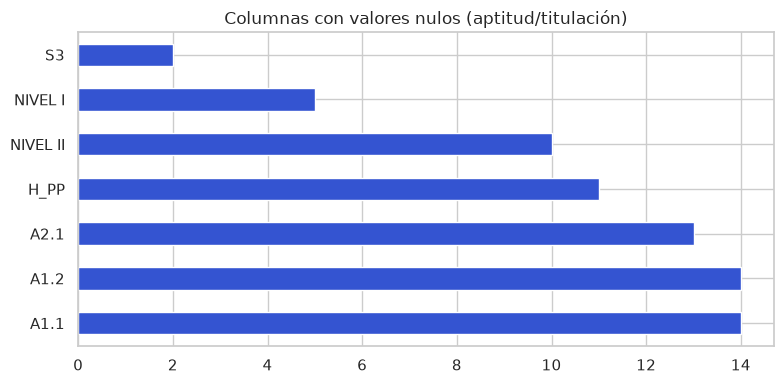

In [4]:
nulls = df.isna().sum()
nulls = nulls[nulls > 0].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 4))
nulls.plot(kind="barh", ax=ax, color="#3454d1")
ax.set_title("Columnas con valores nulos (aptitud/titulación)")
plt.tight_layout()
plt.show()

## 3. Promedio (`PROM`) y aptitud general

            PROM
count  15.000000
mean   34.773333
std     2.011139
min    31.260000
25%    33.695000
50%    34.940000
75%    35.775000
max    38.670000

Tasa de APTO GENERAL = SI: 0.0%  (0 de 15)

COND_N:
COND_N
PENDIENTE    15
Name: count, dtype: int64


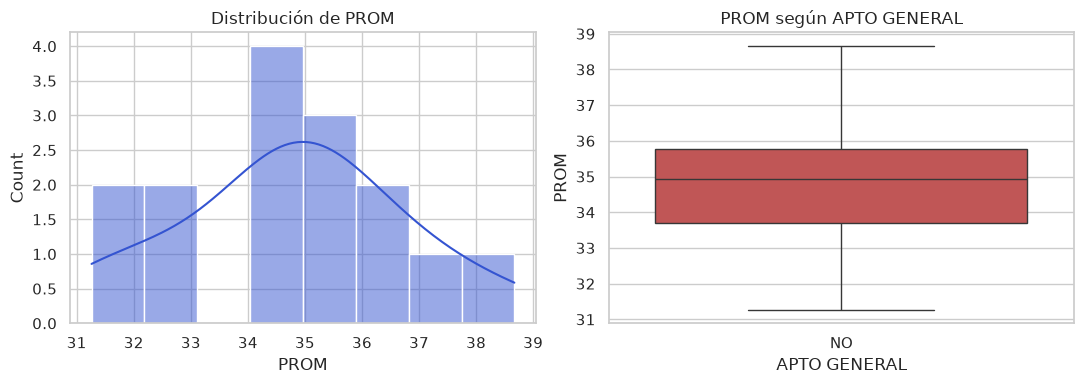

In [5]:
print(df["PROM"].describe().to_frame("PROM"))

tasa_apto = (df["APTO GENERAL"] == "SI").mean()
print(f"\nTasa de APTO GENERAL = SI: {tasa_apto:.1%}  ({(df['APTO GENERAL']=='SI').sum()} de {len(df)})")
print("\nCOND_N:")
print(df["COND_N"].value_counts())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["PROM"], bins=8, kde=True, ax=axes[0], color="#3454d1")
axes[0].set_title("Distribución de PROM")
sns.boxplot(
    data=df, x="APTO GENERAL", y="PROM", hue="APTO GENERAL", legend=False,
    palette={"SI": "#1a9e6b", "NO": "#d14545"}, ax=axes[1],
)
axes[1].set_title("PROM según APTO GENERAL")
plt.tight_layout()
plt.show()

## 4. Por carrera

In [6]:
resumen_carrera = df.groupby("CARRERA").agg(
    n_estudiantes=("N°", "count"),
    prom_promedio=("PROM", "mean"),
    aptos=("APTO GENERAL", lambda s: (s == "SI").sum()),
).round(2)
resumen_carrera

,n_estudiantes,prom_promedio,aptos
CARRERA,,,
DISEÑO GRAFICO,2,35.92,0
GASTRONOMIA,1,31.26,0
TECNICO SUPERIOR EN ENFERMERIA,12,34.88,0


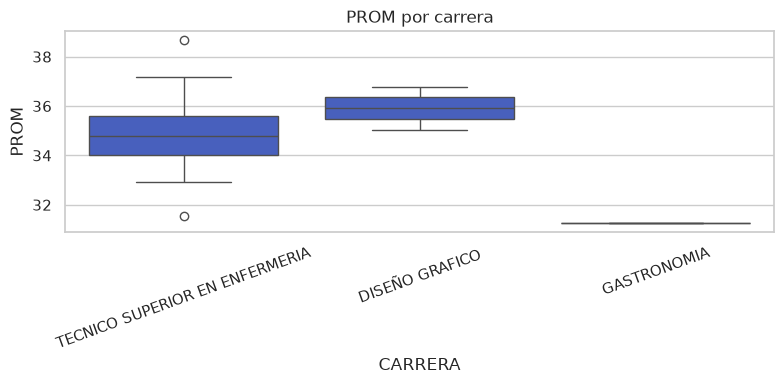

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=df, x="CARRERA", y="PROM", color="#3454d1", ax=ax)
ax.set_title("PROM por carrera")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

## 5. Proceso de titulación: tipo, estado y vinculación

⚠️ `TIPO DE PROYEC. TITULACIÓN`, `ESTADO DEL PROYECTO` y `TUTOR PROYECTO` venían 100% vacíos (anonimizados/no registrados) en el archivo original; en esta copia de trabajo se rellenaron con categorías ficticias solo para poder probar el pipeline. Los gráficos de esta sección **no reflejan decisiones reales** del instituto — se incluyen únicamente para validar que el resto del análisis (agrupar, graficar) funciona una vez la institución entregue estos campos con datos reales.

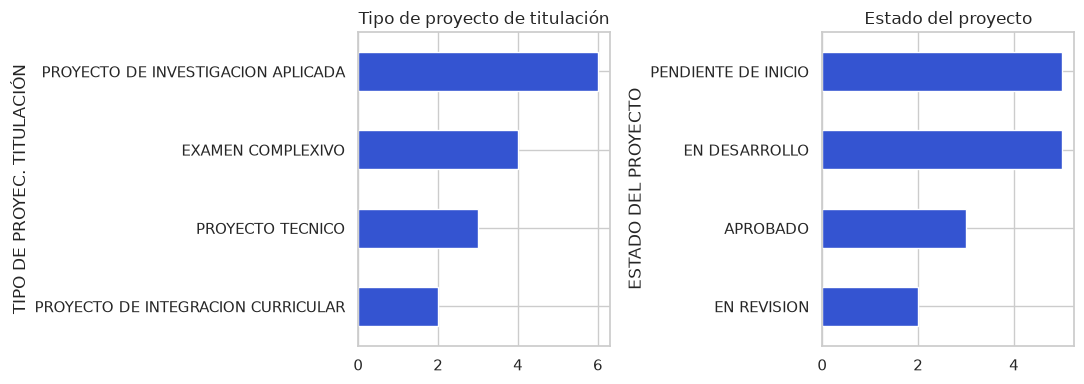

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

df["TIPO DE PROYEC. TITULACIÓN"].value_counts().plot(kind="barh", ax=axes[0], color="#3454d1")
axes[0].set_title("Tipo de proyecto de titulación")
axes[0].invert_yaxis()

df["ESTADO DEL PROYECTO"].value_counts().plot(kind="barh", ax=axes[1], color="#3454d1")
axes[1].set_title("Estado del proyecto")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

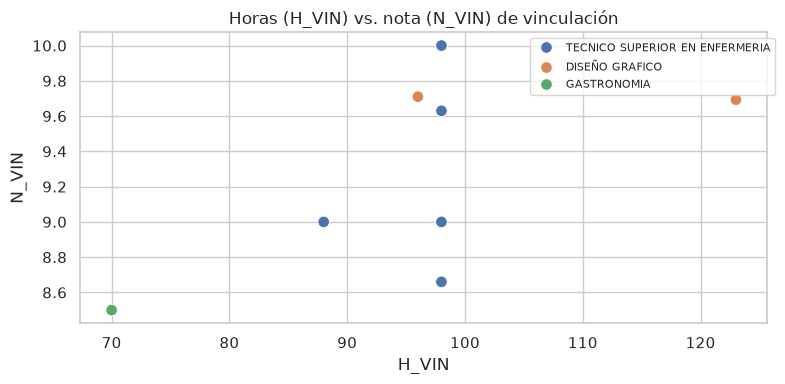

,H_VIN,N_VIN
count,15.00000,15.000000
mean,97.00000,9.523556
std,10.34408,0.582559
min,70.00000,8.500000
25%,98.00000,9.000000
50%,98.00000,9.710000
75%,98.00000,10.000000
max,123.00000,10.000000


In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.scatterplot(data=df, x="H_VIN", y="N_VIN", hue="CARRERA", s=70, ax=ax)
ax.set_title("Horas (H_VIN) vs. nota (N_VIN) de vinculación")
ax.legend(bbox_to_anchor=(1.02, 1), fontsize=8)
plt.tight_layout()
plt.show()

df[["H_VIN", "N_VIN"]].describe()

## 6. Hallazgos preliminares

- **Tamaño de muestra:** N = 15 estudiantes en proceso de titulación, de un solo periodo y repartidos en 3 carreras muy desiguales (12 Enfermería, 2 Diseño Gráfico, 1 Gastronomía) — insuficiente para comparar carreras entre sí.
- **Promedio (`PROM`):** media 34.8 ± 2.0 (mín. 31.3, máx. 38.7) — grupo bastante homogéneo, sin outliers marcados.
- **Aptitud general:** 0% de los 15 están marcados como `APTO GENERAL = SI` — consistente con que **el 100% sigue en condición `PENDIENTE`** (`COND_N`); es decir, a la fecha de corte ninguno ha completado el proceso, no que hayan reprobado.
- **Vinculación:** en promedio 97 horas y nota 9.52/10 — casi todos cerca del máximo (mediana H_VIN = 98h, N_VIN = 9.71), sin relación aparente entre más horas y mejor nota en una muestra tan chica.
- **Niveles de inglés (`A1.1`-`A2.2`):** registro muy disperso y mayormente nulo — no alcanza para concluir nivel de dominio del grupo; conviene revisar con la institución si el proceso de evaluación de inglés está completo para este corte.
- Las columnas de proceso de titulación (tipo, estado, tutor) no tienen valores reales todavía — cualquier indicador sobre "avance de titulación" deberá esperar a que el ISTS las complete.

**Siguiente paso sugerido:** repetir con un corte más adelante en el mismo periodo (cuando `COND_N`/`APTO GENERAL` ya no sean 100% "pendiente") para poder medir una tasa de aptitud real, y con la info de tipo/estado de proyecto ya cargada por la institución.

## 7. Exportar dataset limpio

Se guarda el DataFrame ya reconstruido (con la columna `CARRERA` recuperada de los banners de sección) como `.xlsx`, para no tener que repetir la reconstrucción del encabezado cada vez.

In [10]:
import os

OUT_DIR = "../data/clean"
os.makedirs(OUT_DIR, exist_ok=True)
OUT_FILE = os.path.join(OUT_DIR, "aptitud_limpio.xlsx")

df.to_excel(OUT_FILE, sheet_name="formato_aptitud", index=False)
print(f"Guardado: {OUT_FILE}  ({df.shape[0]} filas x {df.shape[1]} columnas)")

Guardado: ../data/clean/aptitud_limpio.xlsx  (15 filas x 24 columnas)
